In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import requests

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
# Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

Task 1: Data Preprocessing and Cleaning

In [45]:
import os
csv_files = [file for file in os.listdir() if file.endswith('.csv')]
df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
text_col = None
for col in df.columns:
    if df[col].dtype == 'object':
        text_col = col
        break

print(f"Data loaded successfully! Total combined records: {len(df)}")
display(df.head())

Data loaded successfully! Total combined records: 118215


,Date,Source,Headlines,Teaser,Category
0,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,NaN
1,"June, 2001",Medscape Pharmacotherapy,MEDLINE Abstracts: Chronic Nonmalignant Back Pain,A collection of MEDLINE abstracts from the edi...,NaN
2,"November, 2001",Journal of the Southern Orthopaedic Association,Isthmic Spondylolisthesis and Spondylolysis,Despite the large number of treatment options ...,NaN
3,"December, 2001",Current Medical Research and Opinion,Cizolirtine Citrate in the Treatment of Chroni...,Learn more about a novel non-opioid analgesic ...,NaN
4,"February, 2002",Pharmacotherapy,Management of Opioid-Induced Gastrointestinal ...,Awareness of side effects when managing pain w...,NaN


In [46]:
def preprocess_text(text):

    # 1. Lowercasing
    text = text.lower()

    # 2. Punctuation removal
    text = text.translate(str.maketrans('', '', string.punctuation))

    # 3. Tokenization
    tokens = word_tokenize(text)

    # 4. Stop-word removal + Custom Date Filtering
    stop_words = set(stopwords.words('english'))
    months = {'january', 'february', 'march', 'april', 'may', 'june',
              'july', 'august', 'september', 'october', 'november', 'december'}
    stop_words = stop_words.union(months)

    # Keep only alphabetic words (removes years/numbers) that are not stop words and are > 2 letters
    tokens = [word for word in tokens if word not in stop_words and word.isalpha() and len(word) > 2]


    # 5. Lemmatization
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Rejoin tokens into a cleaned string for analysis
    return " ".join(tokens)

# Apply the function to our dataset
df['cleaned_text'] = df[text_col].apply(preprocess_text)

print("Cleaned Text Samples")
display(df[[text_col, 'cleaned_text']].head())

Cleaned Text Samples


,Date,cleaned_text
0,"March, 2000",
1,"June, 2001",
2,"November, 2001",
3,"December, 2001",
4,"February, 2002",


Task 2: Exploratory Text Analysis

In [47]:
from collections import Counter
from wordcloud import WordCloud

# Combine all cleaned text into one massive string to count words
all_words_string = " ".join(df['cleaned_text'])
all_words_list = all_words_string.split()

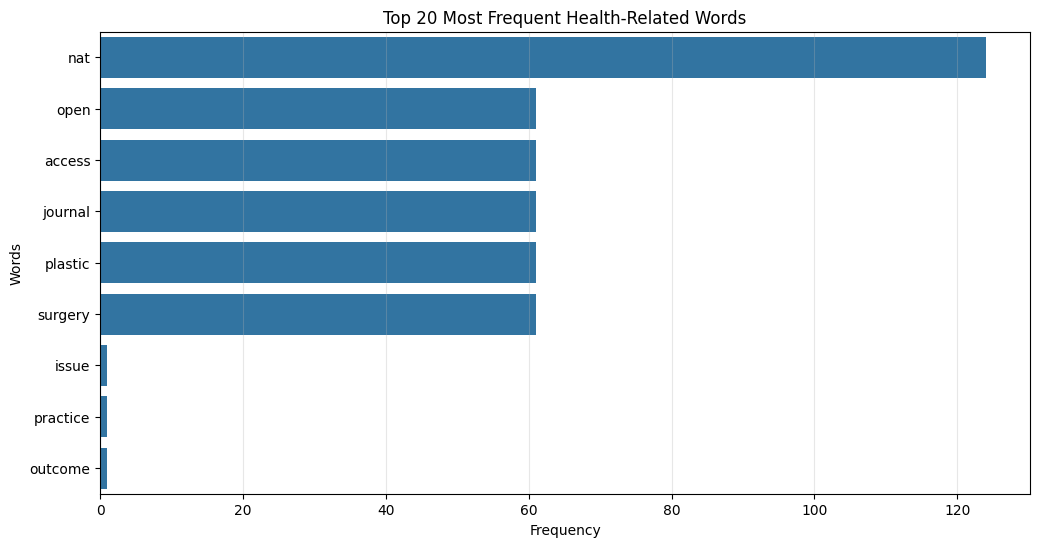

In [48]:
# 1. Word Frequency Distribution
word_counts = Counter(all_words_list)
top_20_words = word_counts.most_common(20)
words, counts = zip(*top_20_words)

# 2. Plot top 20 frequent words
plt.figure(figsize=(12, 6))
sns.barplot(x=list(counts), y=list(words))
plt.title('Top 20 Most Frequent Health-Related Words')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.grid(axis='x', alpha=0.3)
plt.show()


Generating Word Cloud


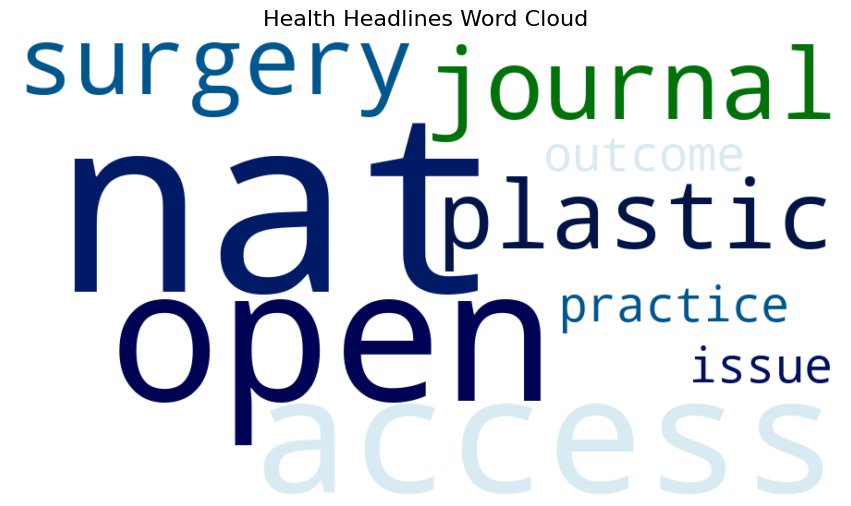

In [78]:
# 3. Word Cloud
print("Generating Word Cloud")
wordcloud = WordCloud(width=900, height=500,
                      background_color='white',
                      colormap='ocean',
                      max_words=100).generate_from_frequencies(word_counts)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Health Headlines Word Cloud', fontsize=16)
plt.show()

Task 3: Topic Modelling using LDA

In [79]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Convert the text into a Document-Term Matrix
# We filter out extremely common or rare words to improve topic quality
vectorizer = CountVectorizer(max_df=0.90, min_df=2, stop_words='english')
dtm = vectorizer.fit_transform(df['cleaned_text'])

# Initialize and fit the LDA model (We will look for 5 dominant topics)
num_topics = 5
lda_model = LatentDirichletAllocation(n_components=num_topics, random_state=42)
lda_model.fit(dtm)

# Retrieve feature names (words) to map them back to the topics
feature_names = vectorizer.get_feature_names_out()

print(f"Top 5 words per topic (Out of {num_topics} topics identified):")
for index, topic in enumerate(lda_model.components_):
    # argsort() sorts in ascending order, so we take the last 5 elements
    top_5_words = [feature_names[i] for i in topic.argsort()[-5:]]
    print(f"Topic #{index + 1}: {', '.join(top_5_words)}")

Top 5 words per topic (Out of 5 topics identified):
Topic #1: access, open, surgery, journal, plastic
Topic #2: journal, open, plastic, surgery, nat
Topic #3: surgery, journal, open, access, nat
Topic #4: journal, open, plastic, surgery, nat
Topic #5: open, access, surgery, journal, nat


In [80]:
import pyLDAvis
import pyLDAvis.lda_model
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Enable notebook rendering for Colab
pyLDAvis.enable_notebook()

# Prepare the visualization
vis = pyLDAvis.lda_model.prepare(lda_model, dtm, vectorizer)

# Display the interactive HTML object
vis

PreparedData(topic_coordinates=              x    y  topics  cluster       Freq
topic                                           
0      0.352158  0.0       1        1  64.502059
1     -0.305230  0.0       2        1  12.510089
3     -0.302269  0.0       3        1  12.460798
4      0.127667  0.0       4        1   5.263527
2      0.127673  0.0       5        1   5.263527, topic_info=      Term        Freq       Total Category  logprob  loglift
2      nat  113.000000  113.000000  Default   6.0000   6.0000
0   access   63.000000   63.000000  Default   5.0000   5.0000
3     open   63.000000   63.000000  Default   4.0000   4.0000
1  journal   63.000000   63.000000  Default   3.0000   3.0000
5  surgery   63.000000   63.000000  Default   2.0000   2.0000
4  plastic   63.000000   63.000000  Default   1.0000   1.0000
4  plastic   55.306613   63.145789   Topic1  -1.6101   0.3059
5  surgery   55.306613   63.145789   Topic1  -1.6101   0.3059
1  journal   55.306613   63.145789   Topic1  -1.6101   0.3059
3     open   55.306613   63.145789   Topic1  -1.6101   0.3059
0   access   55.306613   63.145789   Topic1  -1.6101   0.3059
2      nat    0.180767  113.271056   Topic1  -7.3335  -6.0019
2      nat   52.857066  113.271056   Topic2  -0.0152   1.3164
4  plastic    0.162243   63.145789   Topic2  -5.8015  -3.8855
5  surgery    0.162243   63.145789   Topic2  -5.8015  -3.8855
1  journal    0.162243   63.145789   Topic2  -5.8015  -3.8855
3     open    0.162243   63.145789   Topic2  -5.8015  -3.8855
0   access    0.162243   63.145789   Topic2  -5.8015  -3.8855
2      nat   52.569014  113.271056   Topic3  -0.0167   1.3149
4  plastic    0.177562   63.145789   Topic3  -5.7073  -3.7913
5  surgery    0.177562   63.145789   Topic3  -5.7073  -3.7913
1  journal    0.177562   63.145789   Topic3  -5.7073  -3.7913
3     open    0.177562   63.145789   Topic3  -5.7073  -3.7913
0   access    0.177562   63.145789   Topic3  -5.7073  -3.7913
5  surgery    3.749669   63.145789   Topic4  -1.7954   0.1206
1  journal    3.749669   63.145789   Topic4  -1.7954   0.1206
0   access    3.749669   63.145789   Topic4  -1.7954   0.1206
3     open    3.749669   63.145789   Topic4  -1.7954   0.1206
4  plastic    3.749669   63.145789   Topic4  -1.7954   0.1206
2      nat    3.832187  113.271056   Topic4  -1.7737  -0.4420
0   access    3.749702   63.145789   Topic5  -1.7954   0.1206
3     open    3.749702   63.145789   Topic5  -1.7954   0.1206
1  journal    3.749702   63.145789   Topic5  -1.7954   0.1206
5  surgery    3.749702   63.145789   Topic5  -1.7954   0.1206
4  plastic    3.749702   63.145789   Topic5  -1.7954   0.1206
2      nat    3.832021  113.271056   Topic5  -1.7737  -0.4420, token_table=      Topic      Freq     Term
term                          
0         1  0.871000   access
0         4  0.063345   access
0         5  0.063345   access
1         1  0.871000  journal
1         4  0.063345  journal
1         5  0.063345  journal
2         2  0.467904      nat
2         3  0.467904      nat
2         4  0.035314      nat
2         5  0.035314      nat
3         1  0.871000     open
3         4  0.063345     open
3         5  0.063345     open
4         1  0.871000  plastic
4         4  0.063345  plastic
4         5  0.063345  plastic
5         1  0.871000  surgery
5         4  0.063345  surgery
5         5  0.063345  surgery, R=6, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 4, 5, 3])